# Домашнее задание. Занятие 11. Мидтерм, этап 1: от сырого файла к чистой таблице

**DataGroup. Курс AI Engineering. Неделя 6**

Это тетрадь вашего мидтерм-проекта. На этапе 1 (домашка занятия 11) вы заполняете разделы 0-9: выбираете датасет и доводите его до чистой таблицы с EDA. На этапе 2 (домашка занятия 12, сам мидтерм) продолжаете **эту же тетрадь**, разделы 10-16: признаки, утечка, baseline и README. Полное ТЗ с критериями и списком датасетов в файле `Midterm_TZ.md`.

**Как работать с тетрадью**

1. Откройте её в Google Colab: «Файл», затем «Загрузить блокнот». Сразу переименуйте в `project.ipynb`: под этим именем она будет лежать в репозитории.
2. **Первой запустите ячейку «Помощники»** ниже. Если перезапустили среду, запустите её снова.
3. Идите по разделам сверху вниз. В каждом разделе есть **«Что сделать»**, ссылка на часть тетради практики занятия 11, где это показано на отелях, пустые ячейки для кода и ячейка **«Вывод»**: её заполняете своими словами.
4. Каждое решение про данные записывайте в журнал: `log("шаг", "что решили", len(df))`.
5. В конце этапа запустите самопроверку (раздел 9), потом «Среда выполнения», затем «Перезапустить сеанс и выполнить все»: тетрадь должна пройти без ошибок.
6. Загрузите тетрадь и файлы в публичный репозиторий на GitHub и сдайте **ссылку на репозиторий** в LMS. Как загрузить, в разделе 9 и в ТЗ.

**Баллы этапа 1: 100.**

| раздел | баллы |
|---|---|
| 0-1. Карточка проекта и первый взгляд | 10 |
| 2-3. Дубли и невозможные значения | 15 |
| 4. Пропуски | 20 |
| 5-6. Типы, даты и выбросы | 15 |
| 7. EDA: 5 графиков с выводами | 20 |
| 8. Функция `clean`, сторожа, журнал, чистый CSV | 10 |
| 9. Репозиторий: публичный, тетрадь с выводами | 10 |

**Данные.** Один датасет из списка в ТЗ или свой, согласованный в чате группы. Вот список коротко, ссылки и подробности в ТЗ:

| датасет | задача | уровень |
|---|---|---|
| клиенты телеком-компании (Telco) | классификация: уйдёт ли клиент | базовый |
| поездки на такси в Нью-Йорке | регрессия: чаевые или стоимость | базовый |
| рейтинги шоколада | регрессия: оценка плитки | базовый |
| банк: телемаркетинг вкладов | классификация: откроет ли вклад | средний |
| восхождения в Гималаях | классификация: дойдёт ли до вершины | средний |
| Airbnb в Нью-Йорке | регрессия: цена ночи | средний |
| песни Spotify | регрессия: популярность трека | средний |
| мебель IKEA | регрессия: цена | средний |
| оценки кофе | регрессия: итоговая оценка | продвинутый |
| дома в Эймсе | регрессия: цена дома | продвинутый |

**Как устроено.** Проверки с баллами здесь нет: работу проверяет преподаватель по критериям из ТЗ. Решения принимаете вы, и главное в каждом разделе не код, а **вывод**: что вы увидели и почему решили именно так. Короткий честный вывод лучше длинного пересказа кода.

**Чем пользоваться.** Помощники ниже: `load_csv`, `passport`, `log` и `show_journal`, `target_plot`, `selfcheck`. Всё остальное из тетради практики занятия 11: её функции можно копировать и менять под свои данные.

**Если застряли.** Каждый раздел ссылается на часть тетради практики, где то же самое сделано на отелях. Задайте вопрос в чате группы, не дожидаясь срока. И ставьте `print` после каждого шага: почти всегда окажется, что в таблице лежит не то, что вы думали.

---
## Помощники

Запустите эту ячейку первой. Она подключает библиотеки и создаёт пять функций для проекта.

In [95]:
from pathlib import Path
from urllib.request import urlretrieve

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA = Path("project_data")
DATA.mkdir(exist_ok=True)
TEAL, ORANGE, RED, NAVY, GRAY = "#278071", "#E0843B", "#B0413E", "#13293E", "#8A94A0"
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 140)


def load_csv(url, name="raw", **options):
    """Скачать CSV по ссылке один раз в папку project_data, дальше читать с диска."""
    path = DATA / f"{name}.csv"
    if not path.exists():
        urlretrieve(url, path)
    return pd.read_csv(path, **options)


def passport(table):
    """Паспорт данных: одна строка на столбец, тип, пропуски, разных значений, пример."""
    return pd.DataFrame({
        "тип": table.dtypes.astype(str),
        "пропусков": table.isna().sum(),
        "доля, %": (table.isna().mean() * 100).round(1),
        "разных": table.nunique(),
        "пример": table.iloc[0],
    })


journal = {}


def log(step, decision, rows):
    """Записать решение в журнал. Повторный запуск с тем же шагом перезаписывает запись."""
    journal[step] = {"решение": decision, "строк": rows}


def show_journal():
    """Журнал решений таблицей."""
    return pd.DataFrame(journal).T


def target_plot(table, groups, target, title, xlabel):
    """Цель по группам. Цель 0 и 1: доля единиц в процентах. Цель число: медиана."""
    is_class = set(table[target].dropna().unique()) <= {0, 1}
    stat = "mean" if is_class else "median"
    result = table.groupby(groups, observed=True)[target].agg([stat, "size"])
    values = result[stat] * 100 if is_class else result[stat]
    overall = table[target].mean() * 100 if is_class else table[target].median()
    fig, ax = plt.subplots(figsize=(7.5, 3.2))
    bars = ax.bar(result.index.astype(str), values, color=TEAL)
    ax.axhline(overall, color=ORANGE, ls="--", label="по всем данным")
    labels = ax.bar_label(bars, fmt="%.0f%%" if is_class else "%.1f", padding=2)
    for label in labels:
        label.set_bbox({"facecolor": "white", "edgecolor": "none", "pad": 1})
    ax.set_ylim(0, max(values.max(), overall) * 1.4)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(f"доля {target} = 1, %" if is_class else f"медиана {target}")
    ax.legend(loc="best")
    if len(result) > 6 or max(len(str(i)) for i in result.index) > 12:
        plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()
    return result.round(3)


def selfcheck(raw_table, clean_table, target):
    """Самопроверка этапа 1: что готово, а что нет."""
    has_target = target in clean_table.columns
    checks = [
        ("цель есть в чистой таблице", has_target),
        ("цель без пропусков", has_target and bool(clean_table[target].notna().all())),
        ("цель числом: класс 0 и 1 или число", has_target and pd.api.types.is_numeric_dtype(clean_table[target])),
        ("в чистой таблице нет пропусков", int(clean_table.isna().sum().sum()) == 0),
        ("полных дублей нет (если есть, объясните в выводе)", not clean_table.duplicated().any()),
        ("осталось больше половины строк", len(clean_table) > len(raw_table) / 2),
        ("в журнале минимум 5 решений", len(journal) >= 5),
    ]
    for name, ok in checks:
        print(("OK   " if ok else "НЕТ  ") + name)
    print(f"строк: было {len(raw_table)}, стало {len(clean_table)}; столбцов: было {raw_table.shape[1]}, стало {clean_table.shape[1]}")


print("помощники готовы")

помощники готовы


---
# Этап 1. Домашка занятия 11

---
## 0. Карточка проекта  ·  вместе с разделом 1: 10 баллов

**Что сделать.** Заполните таблицу ниже (двойной щелчок по ячейке) и укажите ссылку и цель в коде. Пример карточки: часть 1 тетради практики, раздел 1.1.

| вопрос | ответ |
|---|---|
| датасет и ссылка на источник | Рейтинги шоколада (Flavors of Cacao, TidyTuesday 2022-01-18): https://github.com/rfordatascience/tidytuesday/tree/master/data/2022/2022-01-18 |
| что значит одна строка | один экспертный отзыв на одну плитку шоколада: производитель, происхождение бобов, год отзыва, процент какао, состав и оценка |
| цель (столбец) | `rating`, оценка плитки от 1 до 4 (шаг 0,25) |
| тип задачи | регрессия |
| метрика | MAE (средняя абсолютная ошибка, в баллах рейтинга) |
| кому и зачем нужен такой прогноз | производителям и магазинам шоколада: заранее оценить, какой рецепт (процент какао, состав, происхождение бобов) получит высокую оценку экспертов |

In [96]:
DATA_URL = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/master/data/2022/2022-01-18/chocolate.csv"
TARGET = "rating"

---
## 1. Первый взгляд

**Что сделать.**

* загрузить данные: `raw = load_csv(DATA_URL)`, посмотреть `shape` и `head`;
* паспорт данных: `passport(raw)`;
* распределение цели: для класса `value_counts()`, для числа `describe()` и гистограмма;
* если цель текстом («Yes» и «No»), превратить её в 0 и 1, например `(raw[TARGET] == "Yes").astype(int)`, и записать это в журнал.

Пример: часть 1 практики, разделы 1.1-1.4.

In [97]:
raw = load_csv(DATA_URL)
print(raw.shape)
raw.head()

(2530, 10)


,ref,company_manufacturer,company_location,review_date,country_of_bean_origin,specific_bean_origin_or_bar_name,cocoa_percent,ingredients,most_memorable_characteristics,rating
0,2454,5150,U.S.A.,2019,Tanzania,"Kokoa Kamili, batch 1",76%,"3- B,S,C","rich cocoa, fatty, bready",3.25
1,2458,5150,U.S.A.,2019,Dominican Republic,"Zorzal, batch 1",76%,"3- B,S,C","cocoa, vegetal, savory",3.50
2,2454,5150,U.S.A.,2019,Madagascar,"Bejofo Estate, batch 1",76%,"3- B,S,C","cocoa, blackberry, full body",3.75
3,2542,5150,U.S.A.,2021,Fiji,"Matasawalevu, batch 1",68%,"3- B,S,C","chewy, off, rubbery",3.00
4,2546,5150,U.S.A.,2021,Venezuela,"Sur del Lago, batch 1",72%,"3- B,S,C","fatty, earthy, moss, nutty,chalky",3.00


In [98]:
passport(raw)

,тип,пропусков,"доля, %",разных,пример
ref,int64,0,0.0,630,2454
company_manufacturer,object,0,0.0,580,5150
company_location,object,0,0.0,67,U.S.A.
review_date,int64,0,0.0,16,2019
country_of_bean_origin,object,0,0.0,62,Tanzania
specific_bean_origin_or_bar_name,object,0,0.0,1605,"Kokoa Kamili, batch 1"
cocoa_percent,object,0,0.0,46,76%
ingredients,object,87,3.4,21,"3- B,S,C"
most_memorable_characteristics,object,0,0.0,2487,"rich cocoa, fatty, bready"
rating,float64,0,0.0,12,3.25


count    2530.00
mean        3.20
std         0.45
min         1.00
25%         3.00
50%         3.25
75%         3.50
max         4.00
Name: rating, dtype: float64

rating
1.00      4
1.50     10
1.75      3
2.00     33
2.25     17
2.50    166
2.75    333
3.00    523
3.25    464
3.50    565
3.75    300
4.00    112
Name: count, dtype: int64


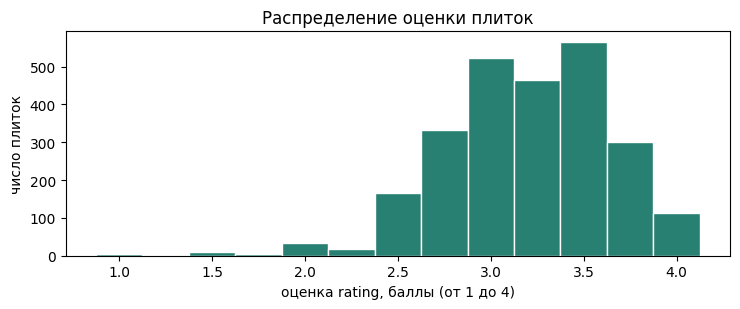

In [99]:
# цель уже число (от 1 до 4), превращать в 0 и 1 не нужно
print(raw[TARGET].describe().round(2))
print()
print(raw[TARGET].value_counts().sort_index())

fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.hist(raw[TARGET], bins=np.arange(0.875, 4.126, 0.25), color=TEAL, edgecolor="white")
ax.set_title("Распределение оценки плиток")
ax.set_xlabel("оценка rating, баллы (от 1 до 4)")
ax.set_ylabel("число плиток")
plt.tight_layout()
plt.show()

log("загрузка", "скачали chocolate.csv по ссылке, 10 столбцов", len(raw))
log("цель", "rating уже число от 1 до 4, преобразование не нужно", len(raw))

**Вывод.** В таблице 2 530 строк и 10 столбцов, одна строка это один отзыв на плитку шоколада. Цель `rating` уже число от 1 до 4 с шагом 0,25, превращать её в 0 и 1 не нужно (у нас регрессия).

Что видно в паспорте: `cocoa_percent` записан текстом («76%»), `ingredients` это строка вида «3- B,S,C» (число ингредиентов и их коды), в `ingredients` есть 87 пропусков, а `ref` это служебный номер записи, а не признак. `review_date` это год целым числом. В `country_of_bean_origin` около 60 разных стран.

Цель распределена как колокол: основная масса оценок (около 86% плиток) лежит между 2,75 и 3,75, медиана 3,25, среднее 3,20. Оценок ниже 2,5 мало, максимальную оценку 4,0 получили 112 плиток. Значит, простая пустышка «всегда предсказывать медиану» уже будет ошибаться не очень сильно.

---
## 2. Дубли  ·  вместе с разделом 3: 15 баллов

**Что сделать.**

* сколько полных дублей: `raw.duplicated().sum()`;
* если в данных есть номер записи (id), то и повторы по нему: `duplicated(subset=["..."])`;
* посмотреть на несколько дублей глазами (`keep=False`) и решить, что это: ошибка выгрузки, одна запись в нескольких местах или разные настоящие строки;
* записать решение в журнал.

Пример: часть 2 практики, разделы 2.1-2.4.

In [100]:
print("полных дублей:", raw.duplicated().sum())

# ref это номер записи в базе, а не id плитки: смотрим, повторяется ли он
print("повторов по ref:", raw["ref"].duplicated().sum(), "из", len(raw))

# повторы по смыслу: та же компания, плитка, происхождение, год и процент какао
key = ["company_manufacturer", "specific_bean_origin_or_bar_name",
       "country_of_bean_origin", "review_date", "cocoa_percent"]
print("повторов по смыслу (без учёта ref и оценки):", raw.duplicated(subset=key).sum())
raw[raw.duplicated(subset=key, keep=False)].sort_values(key).head(10)

полных дублей: 0
повторов по ref: 1900 из 2530
повторов по смыслу (без учёта ref и оценки): 0


,ref,company_manufacturer,company_location,review_date,country_of_bean_origin,specific_bean_origin_or_bar_name,cocoa_percent,ingredients,most_memorable_characteristics,rating


In [101]:
df = raw.drop_duplicates().copy()
log("дубли", f"удалили полные дубли: {len(raw) - len(df)}; повторы ref не дубли, это номер записи", len(df))
print("строк было", len(raw), "стало", len(df))

строк было 2530 стало 2530


**Вывод.** Полных дублей нет, повторов по смыслу (компания, плитка, происхождение бобов, год и процент какао) тоже нет, поэтому строки не удаляем (`drop_duplicates()` оставляем в `clean` как страховку). `ref` повторяется очень часто (630 разных значений на 2 530 строк): это номер записи в базе, у одной партии отзывов он общий, и идентификатором плитки он не является. Поэтому повторы `ref` дублями не считаем.

---
## 3. Невозможные значения и скрытые пропуски

**Что сделать.**

* написать функцию `check_rules(d)`, которая возвращает таблицу флагов: минимум 3 правила здравого смысла (отрицательная цена, ноль там, где ноль невозможен, возраст 150 лет);
* посмотреть на нарушителей глазами и решить по каждому правилу: удалить, исправить или оставить;
* найти скрытые пропуски: `value_counts()` по текстовым столбцам, `describe()` по числовым. Ищите `unknown`, `Undefined`, `?`, пробел, `999`, нули там, где их не бывает;
* записать решения в журнал.

Пример: часть 2 практики, разделы 2.5-2.7.

In [102]:
def to_percent(s):
    """'76%' -> 76.0 (работает и на тексте, и на уже готовых числах)."""
    return pd.to_numeric(s.astype(str).str.replace("%", "", regex=False).str.strip(), errors="coerce")


def check_rules(d):
    """Таблица флагов: True там, где строка нарушает правило."""
    pct = to_percent(d["cocoa_percent"])
    return pd.DataFrame({
        "рейтинг вне 1-4": ~d["rating"].between(1, 4),
        "рейтинг не кратен 0.25": (d["rating"] * 4) % 1 != 0,
        "какао вне 0-100%": ~pct.between(0, 100),
        "год отзыва вне 2006-2021": ~d["review_date"].between(2006, 2021),
        "пустое название компании или плитки": (d["company_manufacturer"].astype(str).str.strip() == "")
                                               | (d["specific_bean_origin_or_bar_name"].astype(str).str.strip() == ""),
    })

In [103]:
rules = check_rules(df)
print("нарушений по каждому правилу:")
print(rules.sum())
print("строк с хотя бы одним нарушением:", rules.any(axis=1).sum())
df[rules.any(axis=1)].head(10)

нарушений по каждому правилу:
рейтинг вне 1-4                        0
рейтинг не кратен 0.25                 0
какао вне 0-100%                       0
год отзыва вне 2006-2021               0
пустое название компании или плитки    0
dtype: int64
строк с хотя бы одним нарушением: 0


,ref,company_manufacturer,company_location,review_date,country_of_bean_origin,specific_bean_origin_or_bar_name,cocoa_percent,ingredients,most_memorable_characteristics,rating


In [104]:
# скрытые пропуски: ищем заглушки в тексте и странные значения в числах
placeholders = ["", "?", "unknown", "unspecified", "n/a", "na", "none", "nan", "-", "--", "not specified"]
text_cols = df.select_dtypes(include=["object", "string"]).columns
for col in text_cols:
    s = df[col].dropna().astype(str)
    bad = s.str.strip().str.lower().isin(placeholders)
    spaces = (s != s.str.strip()).sum()
    print(f"{col:35s} заглушек: {bad.sum():3d}   лишних пробелов по краям: {spaces}")

print()
print(df["country_of_bean_origin"].value_counts().head(8))
print()
print(df[["cocoa_percent", "rating", "review_date"]].apply(lambda s: to_percent(s) if s.name == "cocoa_percent" else s).describe().round(2))

company_manufacturer                заглушек:   0   лишних пробелов по краям: 0
company_location                    заглушек:   0   лишних пробелов по краям: 0
country_of_bean_origin              заглушек:   0   лишних пробелов по краям: 0
specific_bean_origin_or_bar_name    заглушек:   0   лишних пробелов по краям: 0
cocoa_percent                       заглушек:   0   лишних пробелов по краям: 0
ingredients                         заглушек:   0   лишних пробелов по краям: 0
most_memorable_characteristics      заглушек:   0   лишних пробелов по краям: 0

country_of_bean_origin
Venezuela             253
Peru                  244
Dominican Republic    226
Ecuador               219
Madagascar            177
Blend                 156
Nicaragua             100
Bolivia                80
Name: count, dtype: int64

       cocoa_percent   rating  review_date
count        2530.00  2530.00      2530.00
mean           71.64     3.20      2014.37
std             5.62     0.45         3.97
min      

In [105]:
# убираем лишние пробелы по краям в тексте, строки с нарушенными правилами удаляем (если они есть)
for col in df.select_dtypes(include=["object", "string"]).columns:
    df[col] = df[col].str.strip()

before = len(df)
df = df[~check_rules(df).any(axis=1)]
log("пробелы", "убрали лишние пробелы по краям в текстовых столбцах", before)
log("невозможные значения", f"5 правил (рейтинг 1-4 и кратен 0.25, какао 0-100%, год 2006-2021, пустые названия); удалили строк: {before - len(df)}", len(df))
print("строк осталось:", len(df))

строк осталось: 2530


**Вывод.** Я проверила 5 правил здравого смысла: рейтинг от 1 до 4 и кратен 0,25, процент какао от 0 до 100, год отзыва в пределах 2006-2021 и непустые названия компании и плитки. Нарушений нет, поэтому ничего не удалили, но `check_rules` оставили в `clean` как сторожа на случай новой выгрузки.

Скрытые пропуски: заглушек вроде `unknown`, `?` или пробела в текстовых столбцах нет. Значение `Blend` в `country_of_bean_origin` не пропуск, а настоящая категория («смесь бобов из разных стран»), его оставляем. Нулей и значений вроде 999 в числовых столбцах нет: минимальный процент какао около 42, максимальный 100.

---
## 4. Пропуски  ·  20 баллов

**Что сделать.**

* для каждого столбца с пропусками сравнить цель у строк с пропуском и без: `df.groupby(df[col].isna())[TARGET].mean()`;
* решить, что значит пропуск: «не знаем» или «нет»;
* заполнить: «нет» по смыслу (0, «нет»), «не знаем» медианой, самым частым или категорией `Unknown`; если пропуск говорит о строке, сначала флаг; если пропусков больше половины, флаг и удалить столбец;
* заполнить таблицу решений ниже и записать решения в журнал.

По желанию, без баллов: проверить способ заполнения на известных значениях, как в разделе 3.4 практики.

Пример: часть 3 практики.

In [106]:
missing = df.isna().sum()
missing = missing[missing > 0]
print("столбцы с пропусками:")
print(pd.DataFrame({"пропусков": missing, "доля, %": (missing / len(df) * 100).round(1)}))

столбцы с пропусками:
             пропусков  доля, %
ingredients         87      3.4


In [107]:
# пропуск как информация: оценка у строк с пропуском и без
for col in missing.index:
    print(f"\n{col}: оценка у строк с пропуском (True) и без (False)")
    print(df.groupby(df[col].isna())[TARGET].agg(["mean", "median", "size"]).round(2))


ingredients: оценка у строк с пропуском (True) и без (False)
             mean  median  size
ingredients                    
False        3.21    3.25  2443
True         2.81    3.00    87


In [108]:
# ingredients: состав не записан, но он у плитки точно есть: это «не знаем», а не «нет»
# флаг сохраняет сам факт пропуска, а в текст пишем категорию Unknown
df["ingredients_missing"] = df["ingredients"].isna().astype(int)
df["ingredients"] = df["ingredients"].fillna("Unknown")
log("пропуски: ingredients", f"не знаем: флаг ingredients_missing (1 у {df['ingredients_missing'].sum()} строк), в тексте Unknown", len(df))

# страховка: если где-то ещё остались пропуски в тексте, ставим Unknown
for col in df.select_dtypes(include=["object", "string"]).columns:
    n = int(df[col].isna().sum())
    if n:
        df[col] = df[col].fillna("Unknown")
        log(f"пропуски: {col}", f"не знаем: заполнили Unknown ({n} строк)", len(df))

print("пропусков осталось:", int(df.isna().sum().sum()))

пропусков осталось: 0


| столбец | пропусков | «не знаем» или «нет» | что делаем | почему |
|---|---|---|---|---|
| `ingredients` | 87 (около 3,4%) | не знаем | флаг `ingredients_missing`, в тексте `Unknown`; число ингредиентов заполняем самым частым значением | у любой плитки есть состав (минимум какао-бобы), его просто не записали, поэтому это «не знаем», а не «нет»; пропусков мало (3%), удалять строки жалко; у строк с пропуском оценка ниже (в среднем 2,81 против 3,21), поэтому сохраняем факт пропуска флагом |
| остальные столбцы | 0 | - | ничего | пропусков нет |

**Вывод.** Пропуски только в `ingredients`: 87 строк из 2 530 (около 3,4%). Это «не знаем», а не «нет»: у плитки не бывает «никакого» состава, поэтому подставлять 0 ингредиентов или удалять строки неправильно. Причём пропуск не случайный: у строк с пропуском средняя оценка 2,81, у остальных 3,21 (медианы 3,00 и 3,25). Поэтому я оставила факт пропуска флагом `ingredients_missing`, а в тексте поставила `Unknown`. Остальные столбцы без пропусков.

---
## 5. Типы и даты  ·  вместе с разделом 6: 15 баллов

**Что сделать.**

* числа, записанные текстом, превратить в числа: `pd.to_numeric(s, errors="coerce")`, и посмотреть, что попало в пропуски;
* текст с единицами («76%», «SR 1,385», «1800-2200») разобрать: `str.replace`, `str.extract`;
* даты превратить в даты: `pd.to_datetime`, и достать из них признаки: месяц, день недели, час, разницу дат;
* показать `dtypes` после исправлений.

Если в ваших данных нет ни дат, ни чисел текстом, напишите это в выводе: так тоже бывает.

Пример: часть 4 практики, разделы 4.1-4.3.

In [109]:
# 1) процент какао: текст "76%" -> число 76.0
print("до:", df["cocoa_percent"].head(3).tolist(), df["cocoa_percent"].dtype)
df["cocoa_percent"] = to_percent(df["cocoa_percent"])
print("после:", df["cocoa_percent"].head(3).tolist(), df["cocoa_percent"].dtype)
log("тип: cocoa_percent", "текст '76%' -> число 76.0", len(df))

# 2) состав: "3- B,S,C" -> число ингредиентов и флаги по кодам
#    B какао-бобы, S сахар, S* другой подсластитель, C какао-масло, V ваниль, L лецитин, Sa соль
df["n_ingredients"] = pd.to_numeric(df["ingredients"].str.extract(r"^(\d+)")[0])
codes = df["ingredients"].str.extract(r"-\s*(.+)$")[0].fillna("").str.split(",").apply(lambda l: {t.strip() for t in l})
for name, code in [("has_sugar", "S"), ("has_sweetener", "S*"), ("has_cocoa_butter", "C"),
                   ("has_vanilla", "V"), ("has_lecithin", "L"), ("has_salt", "Sa")]:
    df[name] = codes.apply(lambda t, c=code: c in t).astype(int)

# у Unknown числа ингредиентов нет: ставим самое частое значение (флаг ingredients_missing это помнит)
mode_n = int(df["n_ingredients"].mode()[0])
df["n_ingredients"] = df["n_ingredients"].fillna(mode_n)
log("тип: ingredients", f"разобрали строку: n_ingredients и 6 флагов; для Unknown n_ingredients = {mode_n} (самое частое)", len(df))
df[["ingredients", "n_ingredients", "has_sugar", "has_sweetener", "has_cocoa_butter", "has_vanilla", "has_lecithin", "has_salt"]].head()

до: ['76%', '76%', '76%'] object
после: [76.0, 76.0, 76.0] float64


,ingredients,n_ingredients,has_sugar,has_sweetener,has_cocoa_butter,has_vanilla,has_lecithin,has_salt
0,"3- B,S,C",3.0,1,0,1,0,0,0
1,"3- B,S,C",3.0,1,0,1,0,0,0
2,"3- B,S,C",3.0,1,0,1,0,0,0
3,"3- B,S,C",3.0,1,0,1,0,0,0
4,"3- B,S,C",3.0,1,0,1,0,0,0


In [110]:
# даты: review_date это год целым числом, полной даты нет, to_datetime не нужен
print(df["review_date"].dtype, df["review_date"].min(), "-", df["review_date"].max())

# ref это служебный номер записи, не признак: убираем
df = df.drop(columns=["ref"]).reset_index(drop=True)
log("столбец ref", "удалили: служебный номер записи, не признак", len(df))

df.dtypes

int64 2006 - 2021


,0
company_manufacturer,object
company_location,object
review_date,int64
country_of_bean_origin,object
specific_bean_origin_or_bar_name,object
cocoa_percent,float64
ingredients,object
most_memorable_characteristics,object
rating,float64
ingredients_missing,int64


**Вывод.** Текстом вместо числа были две вещи: `cocoa_percent` («76%») превратили в число 76.0, а `ingredients` («3- B,S,C») разобрали на число ингредиентов `n_ingredients` и шесть флагов по кодам (сахар, другой подсластитель, какао-масло, ваниль, лецитин, соль). Для 87 строк с `Unknown` числа ингредиентов нет, поставили самое частое значение, а факт пропуска остался во флаге.

Полных дат в данных нет: `review_date` это год целым числом, поэтому `to_datetime` не нужен, оставляем год как есть. Служебный номер `ref` удалили.

---
## 6. Выбросы

**Что сделать.**

* для главных числовых столбцов найти кандидатов в выбросы: граница IQR или процентили (`quantile(0.999)`);
* по каждому решить: ошибка (удалить или исправить) или редкость (оставить, обрезать `clip`, сжать `np.log1p`);
* для длинного хвоста показать гистограммы до и после логарифма;
* записать решения в журнал.

Пример: часть 4 практики, разделы 4.4-4.6.

In [111]:
def iqr_table(d, cols):
    """Границы IQR и число значений за ними."""
    rows = []
    for c in cols:
        q1, q3 = d[c].quantile([0.25, 0.75])
        iqr = q3 - q1
        lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        rows.append({"столбец": c, "min": d[c].min(), "нижняя граница": lo, "верхняя граница": hi, "max": d[c].max(),
                     "ниже": int((d[c] < lo).sum()), "выше": int((d[c] > hi).sum()),
                     "skew": d[c].skew()})
    return pd.DataFrame(rows).set_index("столбец").round(2)


num_cols = ["cocoa_percent", TARGET, "n_ingredients", "review_date"]
print(iqr_table(df, num_cols))
print()
print("самые низкие оценки:")
print(df.nsmallest(5, TARGET)[["company_manufacturer", "cocoa_percent", "ingredients", TARGET]])
print("самый низкий и самый высокий процент какао:")
print(df.sort_values("cocoa_percent").iloc[[0, 1, -2, -1]][["company_manufacturer", "cocoa_percent", TARGET]])

                  min  нижняя граница  верхняя граница     max  ниже  выше  skew
столбец                                                                         
cocoa_percent    42.0           64.00            80.00   100.0   115   120  1.20
rating            1.0            2.25             4.25     4.0    50     0 -0.61
n_ingredients     1.0           -1.00             7.00     6.0     0     0  0.58
review_date    2006.0         2003.00          2027.00  2021.0     0     0 -0.18

самые низкие оценки:
     company_manufacturer  cocoa_percent   ingredients  rating
430             Callebaut           70.0       Unknown     1.0
590       Claudio Corallo          100.0       Unknown     1.0
632    Cote d' Or (Kraft)           70.0       Unknown     1.0
1679  Neuhaus (Callebaut)           73.0  5- B,S,C,V,L     1.0
293                Bonnat          100.0       Unknown     1.5
самый низкий и самый высокий процент какао:
        company_manufacturer  cocoa_percent  rating
578   Chokolat Elo

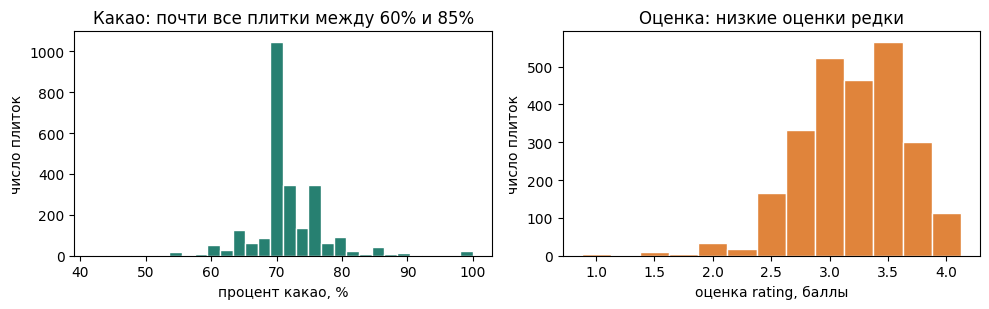

In [112]:
# гистограммы: нужен ли логарифм
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].hist(df["cocoa_percent"], bins=30, color=TEAL, edgecolor="white")
axes[0].set_title("Какао: почти все плитки между 60% и 85%")
axes[0].set_xlabel("процент какао, %")
axes[0].set_ylabel("число плиток")
axes[1].hist(df[TARGET], bins=np.arange(0.875, 4.126, 0.25), color=ORANGE, edgecolor="white")
axes[1].set_title("Оценка: низкие оценки редки")
axes[1].set_xlabel("оценка rating, баллы")
axes[1].set_ylabel("число плиток")
plt.tight_layout()
plt.show()

log("выбросы", "оставили все: значения реальные (какао 42-100%, низкие оценки); логарифм не нужен, хвосты короткие", len(df))

**Вывод.** По правилу IQR выбросы есть у `cocoa_percent` (115 ниже границы и 120 выше: плитки 42-60% и 80-100%) и у `rating` (50 низких оценок, высоких выбросов нет). У `n_ingredients` и `review_date` выбросов нет. У какао так много «выбросов» (около 9%), потому что основная масса очень узкая: половина плиток лежит между 70% и 74%. Я посмотрела крайние значения: это настоящие плитки (в том числе со 100% какао), а не ошибки. Низкие оценки тоже настоящие, причём из 4 плиток с оценкой 1,0 у трёх не записан состав. Все значения лежат в допустимых границах из раздела 3, поэтому ничего не удаляем и не обрезаем.

Логарифм не нужен: у какао перекос умеренный (skew 1,2), у остальных столбцов небольшой, а диапазоны узкие (какао 42-100%, оценка 1-4).

---
## 7. EDA: пять графиков  ·  20 баллов

**Что сделать.** Минимум 5 графиков. У каждого заголовок-вывод (не «lead_time и is_canceled», а «Чем раньше бронь, тем чаще отмена»), подписи осей с единицами и 1-3 предложения под графиком.

| график | на какой вопрос отвечает |
|---|---|
| распределение цели | какая доля классов или как распределено число |
| цель по 3-4 сильным признакам | что сильнее всего связано с целью |
| цель по времени или по группам | меняется ли картина по сезонам, городам, категориям |
| находка | что удивило: парадокс или подозрительно идеальный признак |

`target_plot(df, группы, TARGET, "заголовок-вывод", "подпись оси x")` рисует цель по группам. Числовой признак сначала разбейте на интервалы: `pd.cut(df["столбец"], [границы])`. Для двух числовых столбцов подойдёт `plt.scatter`.

Пример: часть 6 практики.

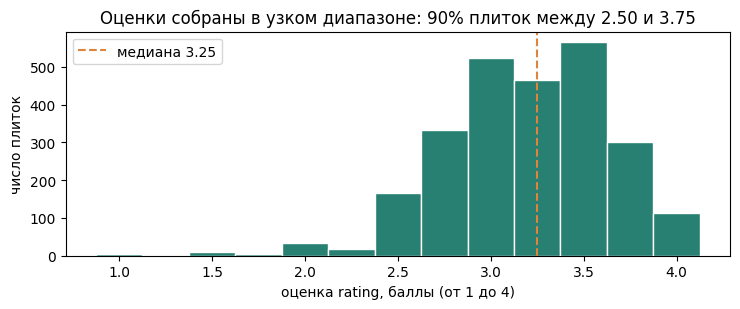

In [113]:
# график 1: распределение цели
med = df[TARGET].median()
p5, p95 = df[TARGET].quantile([0.05, 0.95])
fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.hist(df[TARGET], bins=np.arange(0.875, 4.126, 0.25), color=TEAL, edgecolor="white")
ax.axvline(med, color=ORANGE, ls="--", label=f"медиана {med:.2f}")
ax.set_title(f"Оценки собраны в узком диапазоне: 90% плиток между {p5:.2f} и {p95:.2f}")
ax.set_xlabel("оценка rating, баллы (от 1 до 4)")
ax.set_ylabel("число плиток")
ax.legend()
plt.tight_layout()
plt.show()

**Что видно на графике 1.** Оценки не размазаны от 1 до 4, а собраны в середине шкалы: основная масса (около 86%) между 2,75 и 3,75, пик у 3,0-3,5. Низкие оценки (ниже 2,5) редки, оценку 4,0 получили 112 плиток. Из-за такой узкой «горки» пустышка с медианой уже даёт небольшую ошибку, и улучшить её получится только ненамного.

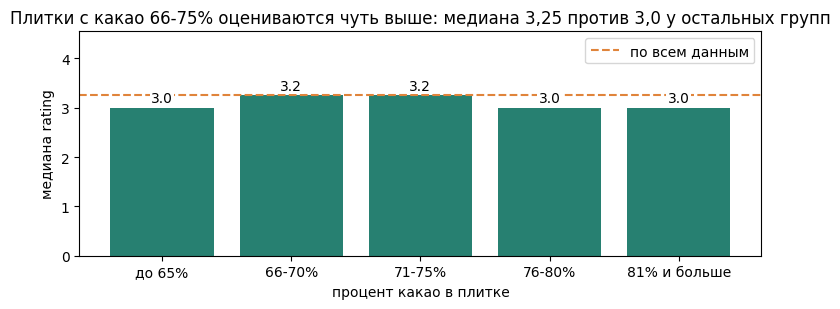

,median,size
cocoa_bin,,
до 65%,3.00,239
66-70%,3.25,1193
71-75%,3.25,789
76-80%,3.00,189
81% и больше,3.00,120


In [114]:
# график 2: оценка по проценту какао
df["cocoa_bin"] = pd.cut(df["cocoa_percent"], [0, 65, 70, 75, 80, 101],
                         labels=["до 65%", "66-70%", "71-75%", "76-80%", "81% и больше"])
by_cocoa = df.groupby("cocoa_bin", observed=True)[TARGET].median()
target_plot(df, df["cocoa_bin"], TARGET,
            "Плитки с какао 66-75% оцениваются чуть выше: медиана 3,25 против 3,0 у остальных групп",
            "процент какао в плитке")

**Что видно на графике 2.** Связь есть, но слабая: разница в одну ступень шкалы (0,25 балла). У плиток с какао 66-70% и 71-75% медиана 3,25, у остальных групп 3,0. Очень тёмные плитки (81% и больше) оцениваются не лучше, а хуже типичных 70-75%: возможно, слишком горький вкус нравится экспертам реже, но это гипотеза, данные причину не показывают. Значит, процент какао это полезный, но не главный признак.

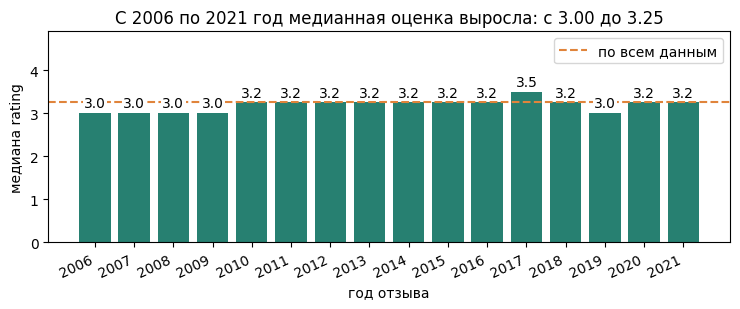

,median,size
review_date,,
2006,3.00,62
2007,3.00,73
2008,3.00,92
2009,3.00,123
2010,3.25,110
2011,3.25,163
2012,3.25,194
2013,3.25,183
2014,3.25,247


In [115]:
# график 3: оценка по годам отзыва
by_year = df.groupby("review_date")[TARGET].median()
y0, y1 = by_year.index.min(), by_year.index.max()
a, b = by_year.loc[y0], by_year.loc[y1]
word = "выросла" if b > a else ("снизилась" if b < a else "не изменилась")
target_plot(df, df["review_date"], TARGET,
            f"С {y0} по {y1} год медианная оценка {word}: с {a:.2f} до {b:.2f}",
            "год отзыва")

**Что видно на графике 3.** До 2009 года медианная оценка 3,0, с 2010 года 3,25. Отдельные скачки (3,5 в 2017 году, когда плиток всего 105, и 3,0 в 2019) устойчивого роста не дают. Возможные причины: в базе накопилось больше хороших производителей или эксперты стали иначе оценивать. Год отзыва можно оставить как признак, но осторожно: он описывает, когда оценили плитку, а не саму плитку.

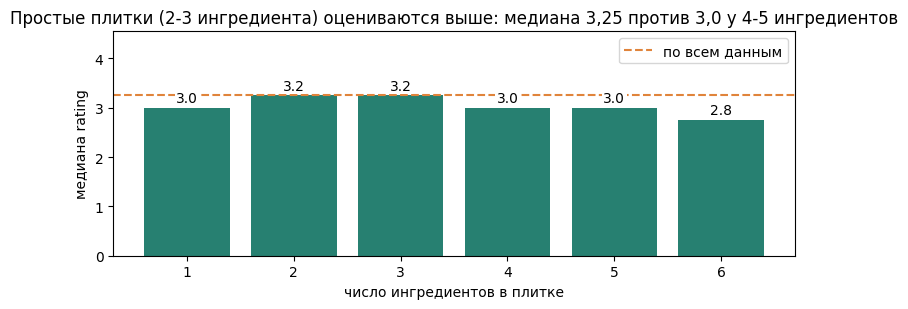

,median,size
n_ingredients,,
1,3.00,6
2,3.25,750
3,3.25,1023
4,3.00,469
5,3.00,191
6,2.75,4


In [116]:
# график 4: оценка по числу ингредиентов (только там, где состав известен)
known = df[df["ingredients_missing"] == 0].copy()
known["n_ingredients"] = known["n_ingredients"].astype(int)
by_n = known.groupby("n_ingredients")[TARGET].median()
target_plot(known, known["n_ingredients"], TARGET,
            "Простые плитки (2-3 ингредиента) оцениваются выше: медиана 3,25 против 3,0 у 4-5 ингредиентов",
            "число ингредиентов в плитке")

**Что видно на графике 4.** Состав связан с оценкой: у простых плиток (2-3 ингредиента) медиана 3,25, у плиток с 4-5 ингредиентами 3,0. Это противоречит интуиции «чем больше ингредиентов, тем лучше»: в шоколаде простота обычно ценится, а добавки (лецитин, ваниль, другие подсластители) возможно маскируют слабое сырьё, но это только гипотеза. Группы с 1 и 6 ингредиентами совсем маленькие (6 и 4 плитки), их медиане верить нельзя.

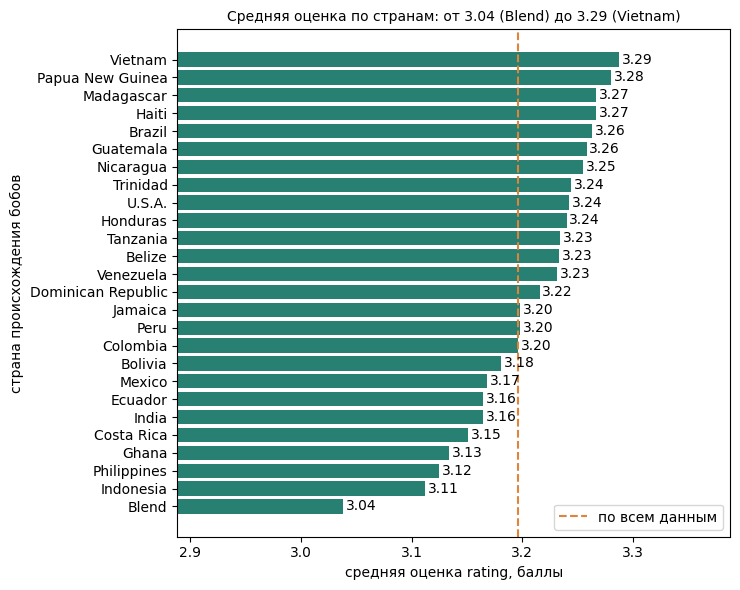

стран с 20+ плитками: 26 из 62


In [117]:
# график 5 (находка): средняя оценка по стране происхождения бобов, только страны с 20 и больше плитками
# (медиана здесь не подходит: оценки идут ступеньками по 0.25, и у большинства стран медиана одинаковая)
g = df.groupby("country_of_bean_origin")[TARGET].agg(["mean", "size"])
g = g[g["size"] >= 20].sort_values("mean")
fig, ax = plt.subplots(figsize=(7.5, 6))
bars = ax.barh(g.index, g["mean"], color=TEAL)
ax.axvline(df[TARGET].mean(), color=ORANGE, ls="--", label="по всем данным")
ax.bar_label(bars, fmt="%.2f", padding=2)
ax.set_xlim(g["mean"].min() - 0.15, g["mean"].max() + 0.1)
ax.set_title(f"Средняя оценка по странам: от {g['mean'].min():.2f} ({g['mean'].idxmin()}) до {g['mean'].max():.2f} ({g['mean'].idxmax()})", fontsize=10)
ax.set_xlabel("средняя оценка rating, баллы")
ax.set_ylabel("страна происхождения бобов")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()
print("стран с 20+ плитками:", len(g), "из", df["country_of_bean_origin"].nunique())

Что видно на графике 5. Только у 26 из 62 стран происхождения бобов 20 и больше плиток, поэтому графику верим только для них; остальные страны редкие, их на этапе 2 придётся объединить в Other. Средняя оценка меняется от 3,04 (смеси Blend) до 3,29 (Вьетнам) при средней по всем данным около 3,20, то есть примерно на 0,25 балла. Выше всех бобы из Вьетнама, Папуа-Новой Гвинеи, Мадагаскара, Гаити, Бразилии и Гватемалы (3,26-3,29). Ниже всех смеси Blend (это не страна, а плитки из бобов разных стран), среди стран ниже всех Индонезия, Филиппины, Гана, Коста-Рика, Индия и Эквадор (3,11-3,16). Различия небольшие: у 22 из 26 значений средняя оценка между 3,15 и 3,29, а ось на графике начинается не с нуля, поэтому разница выглядит больше, чем на самом деле. Страна связана с оценкой, но слабо.

**Вывод по EDA.**

* Цель распределена узко: около 86% оценок между 2,75 и 3,75, медиана 3,25. Пустышка с медианой уже даёт небольшую ошибку.
* Процент какао связан с оценкой слабо: лучше всего плитки 66-75% (медиана 3,25), а очень тёмные (81% и больше) и очень светлые (до 65%) чуть ниже (3,0).
* Состав важен: простые плитки (2-3 ингредиента) оцениваются выше (3,25), чем плитки с 4-5 ингредиентами (3,0).
* Пропуск состава не случаен: у 87 плиток без записанного состава средняя оценка 2,81 против 3,21, и из 4 плиток с оценкой 1,0 у трёх состав не записан.
* Страна происхождения бобов связана с оценкой слабо: у 26 стран с 20 и больше плитками средняя оценка меняется от 3,04 (смеси Blend) до 3,29 (Вьетнам). Остальные 36 стран редкие, их нужно будет объединять в Other.
* Во времени оценки меняются мало: с 2010 года медиана 3,25 с отдельными скачками, поэтому год отзыва слабый признак, и он описывает эксперта и базу, а не плитку.

---
## 8. Функция clean, сторожа и журнал  ·  10 баллов

**Что сделать.**

* собрать все решения разделов 2-6 в одну функцию `clean(raw_table)`: на входе сырая таблица, на выходе чистая;
* проверить, что `clean(raw)` даёт ту же таблицу, что пошаговая очистка;
* сторожа: `assert` на главные правила, например «нет пропусков», «нет невозможных значений»;
* показать журнал: `show_journal()`;
* сохранить чистые данные: `clean_df.to_csv("data/<имя>_clean.csv", index=False)`.

Пример: часть 9 практики, разделы 9.1-9.4.

In [118]:
def clean(raw_table):
    """Сырая таблица на входе, очищенная на выходе."""
    d = raw_table.copy()

    # 2. дубли
    d = d.drop_duplicates()

    # 3. пробелы по краям и невозможные значения
    for col in d.select_dtypes(include=["object", "string"]).columns:
        d[col] = d[col].str.strip()
    d = d[~check_rules(d).any(axis=1)]

    # 4. пропуски: состав не знаем, флаг + Unknown
    d["ingredients_missing"] = d["ingredients"].isna().astype(int)
    d["ingredients"] = d["ingredients"].fillna("Unknown")
    for col in d.select_dtypes(include=["object", "string"]).columns:
        d[col] = d[col].fillna("Unknown")

    # 5. типы: процент какао и состав
    d["cocoa_percent"] = to_percent(d["cocoa_percent"])
    d["n_ingredients"] = pd.to_numeric(d["ingredients"].str.extract(r"^(\d+)")[0])
    codes = d["ingredients"].str.extract(r"-\s*(.+)$")[0].fillna("").str.split(",").apply(lambda l: {t.strip() for t in l})
    for name, code in [("has_sugar", "S"), ("has_sweetener", "S*"), ("has_cocoa_butter", "C"),
                       ("has_vanilla", "V"), ("has_lecithin", "L"), ("has_salt", "Sa")]:
        d[name] = codes.apply(lambda t, c=code: c in t).astype(int)
    d["n_ingredients"] = d["n_ingredients"].fillna(int(d["n_ingredients"].mode()[0]))

    # 6. выбросы: оставляем, это настоящие редкости (ничего не делаем)

    # служебный номер
    d = d.drop(columns=["ref"]).reset_index(drop=True)
    return d

In [119]:
clean_df = clean(raw)

# та же таблица, что получилась пошаговой очисткой в разделах 2-6
steps_df = df.drop(columns=["cocoa_bin"], errors="ignore")
print("clean(raw) совпадает с пошаговой очисткой:", clean_df.equals(steps_df))

# сторожа
assert clean_df.isna().sum().sum() == 0, "в чистой таблице остались пропуски"
assert not check_rules(clean_df).any(axis=1).any(), "остались невозможные значения"
assert clean_df[TARGET].between(1, 4).all(), "рейтинг вне диапазона 1-4"
assert clean_df["cocoa_percent"].between(0, 100).all(), "процент какао вне диапазона"
assert pd.api.types.is_numeric_dtype(clean_df["cocoa_percent"]), "cocoa_percent не число"
assert not clean_df.duplicated().any(), "остались полные дубли"
assert "ref" not in clean_df.columns, "служебный столбец ref остался"
print("сторожа пройдены, чистая таблица:", clean_df.shape)
log("clean", "собрали все шаги в функцию clean(raw), сторожа assert пройдены", len(clean_df))
clean_df.head()

clean(raw) совпадает с пошаговой очисткой: True
сторожа пройдены, чистая таблица: (2530, 17)


,company_manufacturer,company_location,review_date,country_of_bean_origin,specific_bean_origin_or_bar_name,cocoa_percent,ingredients,most_memorable_characteristics,rating,ingredients_missing,n_ingredients,has_sugar,has_sweetener,has_cocoa_butter,has_vanilla,has_lecithin,has_salt
0,5150,U.S.A.,2019,Tanzania,"Kokoa Kamili, batch 1",76.0,"3- B,S,C","rich cocoa, fatty, bready",3.25,0,3.0,1,0,1,0,0,0
1,5150,U.S.A.,2019,Dominican Republic,"Zorzal, batch 1",76.0,"3- B,S,C","cocoa, vegetal, savory",3.50,0,3.0,1,0,1,0,0,0
2,5150,U.S.A.,2019,Madagascar,"Bejofo Estate, batch 1",76.0,"3- B,S,C","cocoa, blackberry, full body",3.75,0,3.0,1,0,1,0,0,0
3,5150,U.S.A.,2021,Fiji,"Matasawalevu, batch 1",68.0,"3- B,S,C","chewy, off, rubbery",3.00,0,3.0,1,0,1,0,0,0
4,5150,U.S.A.,2021,Venezuela,"Sur del Lago, batch 1",72.0,"3- B,S,C","fatty, earthy, moss, nutty,chalky",3.00,0,3.0,1,0,1,0,0,0


In [120]:
show_journal()

,решение,строк
загрузка,"скачали chocolate.csv по ссылке, 10 столбцов",2530
цель,"rating уже число от 1 до 4, преобразование не нужно",2530
дубли,"удалили полные дубли: 0; повторы ref не дубли, это номер записи",2530
пробелы,убрали лишние пробелы по краям в текстовых столбцах,2530
невозможные значения,"5 правил (рейтинг 1-4 и кратен 0.25, какао 0-100%, год 2006-2021, пустые названия); удалили строк: 0",2530
пропуски: ingredients,"не знаем: флаг ingredients_missing (1 у 87 строк), в тексте Unknown",2530
тип: cocoa_percent,текст '76%' -> число 76.0,2530
тип: ingredients,разобрали строку: n_ingredients и 6 флагов; для Unknown n_ingredients = 3 (самое частое),2530
столбец ref,"удалили: служебный номер записи, не признак",2530
выбросы,"оставили все: значения реальные (какао 42-100%, низкие оценки); логарифм не нужен, хвосты короткие",2530


In [121]:
Path("data").mkdir(exist_ok=True)
clean_df.to_csv("data/chocolate_clean.csv", index=False)
print("сохранено:", Path("data/chocolate_clean.csv").stat().st_size // 1024, "КБ")

сохранено: 289 КБ


---
## 9. Самопроверка и репозиторий  ·  10 баллов

**Самопроверка.** Уберите `#` и запустите. Всё должно быть `OK`, а если где-то `НЕТ` по делу (например, дубли появились после обрезки выбросов, как в части 9 практики), объясните это в выводе.

In [122]:
selfcheck(raw, clean_df, TARGET)

OK   цель есть в чистой таблице
OK   цель без пропусков
OK   цель числом: класс 0 и 1 или число
OK   в чистой таблице нет пропусков
OK   полных дублей нет (если есть, объясните в выводе)
OK   осталось больше половины строк
OK   в журнале минимум 5 решений
строк: было 2530, стало 2530; столбцов: было 10, стало 17


**Репозиторий.**

1. github.com, справа вверху «+», затем «New repository». Имя, например, `midterm-telco`, видимость **Public**, галочку README не ставить.
2. «Среда выполнения», затем «Перезапустить сеанс и выполнить все»: тетрадь проходит без ошибок. Сохраните её.
3. Скачайте тетрадь: «Файл», затем «Скачать», затем «Скачать .ipynb», имя `project.ipynb`. Скачайте чистый CSV из папки `data` на панели файлов слева.
4. На странице репозитория ссылка «uploading an existing file», перетащите `project.ipynb` и папку `data`, «Commit changes» с подписью «этап 1».
5. Откройте ссылку в режиме инкогнито: тетрадь открывается, графики видны. Сдайте ссылку в LMS.

README на этапе 1 можно сделать черновым: название проекта и одна строка о задаче. Полный README это этап 2.

Пример: часть 9 практики, разделы 9.5-9.6.

---
# Этап 2. Мидтерм, домашка занятия 12

Здесь разделы 10-16 в той же тетради: новые признаки, категории, проверка утечки, baseline, выводы, README и финальная проверка.

**Главное правило этапа 2: правило одной строки.** Всё, что считается по одной строке (флаги, разности, части даты), можно делать до деления на train и test. Всё, что считается по многим строкам (медиана для пропусков, среднее и разброс для масштаба, список редких стран, кодирование компании по средней оценке), учится **только на train** и спрятано внутри `Pipeline`. Тогда test остаётся честным «завтрашним днём».

**Метрика:** MAE (средняя абсолютная ошибка в баллах рейтинга, меньше значит лучше). Test трогаем один раз в самом конце раздела 13.

---
## Помощники этапа 2

Запустите ячейку ниже один раз. Она подключает библиотеки scikit-learn и создаёт функции `cv_score`, `test_scores`, `ladder_plot`, `write_requirements`.

In [123]:
import warnings
from importlib import metadata

import joblib
from IPython.display import Markdown, display
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import GridSearchCV, KFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler, TargetEncoder

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

CV = KFold(n_splits=5, shuffle=True, random_state=42)   # одно и то же деление для всех сравнений


def cv_score(model, X_tr, y_tr):
    """MAE на кросс-валидации по train. Подготовка внутри model учится заново на каждом круге."""
    scores = cross_val_score(model, X_tr, y_tr, cv=CV, scoring="neg_mean_absolute_error")
    return -scores.mean()


_test_state = {"used": False}


def test_scores(models, X_te, y_te):
    """MAE на test для словаря {имя: обученная модель}. Вызывать один раз в конце."""
    if _test_state["used"]:
        print("ВНИМАНИЕ: test уже использовали, второй раз это уже не test.")
    _test_state["used"] = True
    return {name: mean_absolute_error(y_te, m.predict(X_te)) for name, m in models.items()}


def ladder_plot(cv, test, title, path=None):
    """График-лестница: MAE на кросс-валидации и на test по ступеням."""
    names = list(cv)
    pos = np.arange(len(names))
    fig, ax = plt.subplots(figsize=(7.5, 3.6))
    bars1 = ax.barh(pos - 0.2, [cv[n] for n in names], 0.4, color=TEAL, label="кросс-валидация на train")
    bars2 = ax.barh(pos + 0.2, [test[n] for n in names], 0.4, color=ORANGE, label="test (один раз)")
    ax.bar_label(bars1, fmt="%.3f", padding=2)
    ax.bar_label(bars2, fmt="%.3f", padding=2)
    ax.set_yticks(pos)
    ax.set_yticklabels(names)
    ax.invert_yaxis()
    ax.set_xlim(0, max(list(cv.values()) + list(test.values())) * 1.25)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("MAE, баллы рейтинга (меньше значит лучше)")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2, frameon=False)
    plt.tight_layout()
    if path:
        Path(path).parent.mkdir(exist_ok=True)
        fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()


def write_requirements(path="requirements.txt", packages=("pandas", "numpy", "matplotlib", "scikit-learn", "joblib")):
    """requirements.txt с версиями библиотек, под которыми тетрадь реально запускалась."""
    lines = [f"{p}=={metadata.version(p)}" for p in packages]
    Path(path).write_text("\n".join(lines) + "\n", encoding="utf-8")
    return lines


print("помощники этапа 2 готовы")

помощники этапа 2 готовы


---
## 10. Новые признаки  ·  10 баллов

**Что сделано.** Четыре признака из смысла задачи. Все считаются по одной строке (по правилу одной строки их можно делать до деления на train и test), поэтому оформлены функцией `add_features`: она станет первым шагом `Pipeline` и сама применится к любой новой плитке.

| признак | как считается | зачем |
|---|---|---|
| `is_blend` | 1, если бобы из смеси стран (`Blend`) | в EDA смеси оказались на последнем месте по средней оценке (3,04 против 3,20 в среднем), флаг даёт это модели напрямую |
| `cocoa_dist70` | модуль разницы между процентом какао и 70 | лучше всего оценивались плитки 66-75%, а в обе стороны от этого оценка падала: линейная модель по самому проценту такой «горб» не уловит, а расстояние до 70 его описывает |
| `n_additives` | число добавок помимо какао, сахара и какао-масла: другой подсластитель, ваниль, лецитин, соль | простые плитки в EDA оценивались выше, чем плитки с длинным списком добавок; одно число проще, чем четыре отдельных флага |
| `made_in_origin` | 1, если компания находится в той же стране, где выращены бобы | гипотеза: производитель в стране происхождения контролирует сырьё от плантации до плитки; проверяем данными ниже, не утверждаем заранее |

In [124]:
def add_features(d):
    """Новые признаки по одной строке. Исходные столбцы остаются на месте."""
    out = d.copy()
    out["is_blend"] = (d["country_of_bean_origin"] == "Blend").astype(int)
    out["cocoa_dist70"] = (d["cocoa_percent"] - 70).abs()
    out["n_additives"] = d[["has_sweetener", "has_vanilla", "has_lecithin", "has_salt"]].sum(axis=1)
    out["made_in_origin"] = (d["company_location"] == d["country_of_bean_origin"]).astype(int)
    return out


feat = add_features(clean_df)
print("новые признаки, первые строки:")
print(feat[["country_of_bean_origin", "cocoa_percent", "is_blend", "cocoa_dist70", "n_additives", "made_in_origin"]].head())

print("\nсредняя оценка по признакам:")
for col in ["is_blend", "made_in_origin", "n_additives"]:
    print(f"\n{col}")
    print(feat.groupby(col)[TARGET].agg(["mean", "size"]).round(2))

feat["cocoa_dist_group"] = pd.cut(feat["cocoa_dist70"], [-0.1, 0, 5, 10, 60], labels=["ровно 70%", "до 5 п.п.", "5-10 п.п.", "больше 10 п.п."])
print("\ncocoa_dist70 по группам")
print(feat.groupby("cocoa_dist_group", observed=True)[TARGET].agg(["mean", "size"]).round(2))

log("новые признаки", "is_blend, cocoa_dist70, n_additives, made_in_origin: функция add_features, считается по одной строке", len(clean_df))

новые признаки, первые строки:
  country_of_bean_origin  cocoa_percent  is_blend  cocoa_dist70  n_additives  made_in_origin
0               Tanzania           76.0         0           6.0            0               0
1     Dominican Republic           76.0         0           6.0            0               0
2             Madagascar           76.0         0           6.0            0               0
3                   Fiji           68.0         0           2.0            0               0
4              Venezuela           72.0         0           2.0            0               0

средняя оценка по признакам:

is_blend
          mean  size
is_blend            
0         3.21  2374
1         3.04   156

made_in_origin
                mean  size
made_in_origin            
0               3.21  2213
1               3.13   317

n_additives
             mean  size
n_additives            
0            3.24  1811
1            3.11   486
2            3.07   226
3            3.00     7

cocoa

In [125]:
# итог по признакам одним числом: во сколько раз меняется оценка между крайними группами
rows = []
for col in ["is_blend", "made_in_origin"]:
    m = feat.groupby(col)[TARGET].mean()
    rows.append({"признак": col, "средняя оценка при 0": m.get(0), "средняя оценка при 1": m.get(1), "разница": m.get(1) - m.get(0)})
m = feat.groupby("n_additives")[TARGET].mean()
rows.append({"признак": "n_additives (0 и максимум)", "средняя оценка при 0": m.iloc[0], "средняя оценка при 1": m.iloc[-1], "разница": m.iloc[-1] - m.iloc[0]})
pd.DataFrame(rows).set_index("признак").round(2)

,средняя оценка при 0,средняя оценка при 1,разница
признак,,,
is_blend,3.21,3.04,-0.17
made_in_origin,3.21,3.13,-0.08
n_additives (0 и максимум),3.24,3.00,-0.24


**Вывод.** Я сделала 4 признака по одной строке, поэтому они не подсматривают в test, и оформила их функцией `add_features`.

Три из четырёх подтвердились таблицами выше. Смеси (`is_blend = 1`) получают среднюю оценку 3,04 против 3,21 у остальных. Чем дальше процент какао от 70, тем ниже оценка: ровно 70% даёт 3,26, а отклонение больше 10 пунктов 2,87. Плитки без добавок оцениваются в среднем на 3,24, с двумя добавками на 3,07 (с тремя добавками всего 7 плиток, этому числу верить нельзя).

Четвёртая гипотеза не подтвердилась: плитки, сделанные в стране происхождения бобов (`made_in_origin = 1`, 317 плиток), оцениваются чуть ниже, 3,13 против 3,21, а не выше, как я ожидала. Объяснить эту разницу я пока не могу. Признак оставляю в модели, но его вклад отдельно я не проверяла.

---
## 11. Категории  ·  10 баллов

**Что сделать.** Превратить категории в числа так, чтобы подготовка помнила решения, принятые на train, и одинаково работала на test и на новой плитке. Простой `get_dummies` для этого не годится: на новой плитке он даёт другой набор столбцов (в уроке 12 это упало с ошибкой).

| столбец | значений | что делаем | почему |
|---|---|---|---|
| `country_of_bean_origin` | около 60 | `OneHotEncoder`, редкие и незнакомые страны в один столбец `infrequent` (это `Other`) | у многих стран меньше 20 плиток, отдельный флаг на них запомнит шум |
| `company_location` | около 65 | то же | та же причина |
| `company_manufacturer` | около 580 | `TargetEncoder`: компания превращается в одно число, среднюю оценку её плиток со сглаживанием | 580 флагов на 2 000 строк это слишком много, а у компании с одной плиткой код без сглаживания равнялся бы её собственной оценке |
| `ingredients`, `specific_bean_origin_or_bar_name`, `most_memorable_characteristics` | много | в модель не идут | состав уже разобран на числа и флаги; название плитки почти уникально (запомнит строку); слова эксперта разберём в разделе 12 |

Деление на train и test делаем здесь: до него только правила по строке, после него всё, что считается по многим строкам, учится на train.

In [127]:
# входные столбцы: всё, кроме цели; деление 80/20 (для регрессии без stratify)
INPUTS = [c for c in clean_df.columns if c != TARGET]
X = clean_df[INPUTS]
y = clean_df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("train:", X_train.shape, " test:", X_test.shape)
print("медиана оценки: train", y_train.median(), " test", y_test.median())

# какие столбцы в какую ветку подготовки идут
num_cols = ["cocoa_percent", "n_ingredients", "review_date", "cocoa_dist70", "n_additives"]
flag_cols = ["has_sugar", "has_sweetener", "has_cocoa_butter", "has_vanilla", "has_lecithin", "has_salt",
             "ingredients_missing", "is_blend", "made_in_origin"]
cat_cols = ["country_of_bean_origin", "company_location"]
company_col = ["company_manufacturer"]


def make_target_encoder():
    """Компания -> одно число (средняя оценка с учётом сглаживания), внутри fit кодирует строку по остальным частям train.
    Работает на любой версии scikit-learn: в новых версиях перемешивание задаётся через cv, в старых через random_state."""
    import sklearn
    if tuple(int(v) for v in sklearn.__version__.split(".")[:2]) >= (1, 9):
        return TargetEncoder(target_type="continuous", smooth="auto", cv=KFold(5, shuffle=True, random_state=42))
    return TargetEncoder(target_type="continuous", smooth="auto", random_state=42)


def make_prep(min_frequency=20, text=False):
    """Вся подготовка одним объектом: add_features, затем ветки чисел, флагов, категорий и компании."""
    branches = [
        ("num", Pipeline([("fill", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), num_cols),
        ("flags", "passthrough", flag_cols),
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=min_frequency, sparse_output=False), cat_cols),
        ("company", make_target_encoder(), company_col),
    ]
    if text:   # только для проверки утечки в разделе 12
        branches.append(("words", CountVectorizer(min_df=15), "most_memorable_characteristics"))
    return Pipeline([("features", FunctionTransformer(add_features)),
                     ("columns", ColumnTransformer(branches, sparse_threshold=0))])


def make_model(estimator, min_frequency=20, text=False):
    """Подготовка и модель в одном Pipeline: на каждом круге кросс-валидации подготовка учится заново."""
    return Pipeline([("prep", make_prep(min_frequency, text)), ("model", estimator)])


prep = make_prep(min_frequency=20)
prep.fit(X_train, y_train)               # подготовка учится только на train
Xt_train = prep.transform(X_train)
Xt_test = prep.transform(X_test)         # test превращается в те же столбцы
print("\nбыло столбцов:", X_train.shape[1], " стало признаков:", Xt_train.shape[1])
print("train:", Xt_train.shape, " test:", Xt_test.shape)
print("пропусков в таблице признаков: train", int(np.isnan(Xt_train).sum()), ", test", int(np.isnan(Xt_test).sum()))
print("все числа:", Xt_train.dtype)

train: (2024, 16)  test: (506, 16)
медиана оценки: train 3.25  test 3.25

было столбцов: 16  стало признаков: 59
train: (2024, 59)  test: (506, 59)
пропусков в таблице признаков: train 0 , test 0
все числа: float64


In [128]:
# как редкие значения ушли в один столбец (это и есть Other)
encoder = prep.named_steps["columns"].named_transformers_["cat"]
for col, cats, rare in zip(cat_cols, encoder.categories_, encoder.infrequent_categories_):
    n_rare = 0 if rare is None else len(rare)
    n_flags = len(cats) if n_rare == 0 else len(cats) - n_rare + 1
    print(f"{col}: значений в train {len(cats)}, редких (меньше 20 плиток) {n_rare}, столбцов-флагов {n_flags}")
print("компаний в train:", X_train["company_manufacturer"].nunique(), "-> один столбец через TargetEncoder")

names = prep.named_steps["columns"].get_feature_names_out()
print("\nпервые и последние имена признаков:")
print(list(names[:6]), "...", list(names[-4:]))
log("категории", f"OneHotEncoder(min_frequency=20, редкие в infrequent) для страны и страны компании; компания через TargetEncoder; признаков {len(names)}", len(X_train))

country_of_bean_origin: значений в train 62, редких (меньше 20 плиток) 38, столбцов-флагов 25
company_location: значений в train 66, редких (меньше 20 плиток) 48, столбцов-флагов 19
компаний в train: 542 -> один столбец через TargetEncoder

первые и последние имена признаков:
['num__cocoa_percent', 'num__n_ingredients', 'num__review_date', 'num__cocoa_dist70', 'num__n_additives', 'flags__has_sugar'] ... ['cat__company_location_U.S.A.', 'cat__company_location_Venezuela', 'cat__company_location_infrequent_sklearn', 'company__company_manufacturer']


In [129]:
display(Markdown(f"""**Вывод.** Деление 80/20 даёт {len(X_train)} плиток в train и {len(X_test)} в test, медиана оценки в обеих частях одинаковая ({y_train.median()} и {y_test.median()}). Подготовка собрана одним объектом и выучена только на train. Из {X_train.shape[1]} столбцов получилось {Xt_train.shape[1]} признаков, все числа и без пропусков (в train {int(np.isnan(Xt_train).sum())}, в test {int(np.isnan(Xt_test).sum())}).
Редкие страны объединены в один столбец `infrequent` (его роль как `Other` из занятия 11, но решение принято по train). Компания ({X_train['company_manufacturer'].nunique()} значений) закодирована одним числом: у компаний с одной плиткой `TargetEncoder` сглаживает код к общей средней, чтобы он не повторял ответ строки."""))

**Вывод.** Деление 80/20 даёт 2024 плиток в train и 506 в test, медиана оценки в обеих частях одинаковая (3.25 и 3.25). Подготовка собрана одним объектом и выучена только на train. Из 16 столбцов получилось 59 признаков, все числа и без пропусков (в train 0, в test 0).
Редкие страны объединены в один столбец `infrequent` (его роль как `Other` из занятия 11, но решение принято по train). Компания (542 значений) закодирована одним числом: у компаний с одной плиткой `TargetEncoder` сглаживает код к общей средней, чтобы он не повторял ответ строки.

---
## 12. Утечка  ·  15 баллов

**Что сделать.** Для каждого подозрительного столбца ответить на вопрос: **когда он становится известен?** Если после того, как плитку оценили, то для новой плитки его не будет, и брать его нельзя. Затем проверить главного подозреваемого моделью: насколько он улучшает прогноз.

Все проверки делаем кросс-валидацией на train, test не трогаем.

In [130]:
leak_table = pd.DataFrame([
    ("company_manufacturer", "до дегустации", "берём", "кто делает плитку, известно заранее; кодируем через TargetEncoder"),
    ("company_location", "до дегустации", "берём", "где находится компания, известно заранее"),
    ("country_of_bean_origin", "до дегустации", "берём", "происхождение бобов известно производителю"),
    ("cocoa_percent, ingredients (n_ingredients и флаги)", "до дегустации", "берём", "это рецепт плитки"),
    ("review_date", "известен заранее (год, когда плитку оценят)", "берём с осторожностью", "описывает эксперта и базу, а не плитку; для будущих лет модель не проверена"),
    ("ingredients_missing", "признак строки в базе", "берём", "для новой плитки с известным составом всегда 0, вреда не наносит"),
    ("specific_bean_origin_or_bar_name", "до дегустации", "не берём", "очень много разных значений: почти название-метка, по нему модель запоминает конкретные плитки, а не закономерности"),
    ("most_memorable_characteristics", "ПОСЛЕ дегустации", "не берём", "слова, которыми эксперт описал вкус после дегустации: для новой плитки их не существует; проверено моделью"),
    ("ref", "служебный номер записи в базе", "не берём", "удалён ещё на этапе 1"),
], columns=["столбец", "когда становится известен", "берём или нет", "почему"])
pd.set_option("display.max_colwidth", 110)
leak_table

,столбец,когда становится известен,берём или нет,почему
0,company_manufacturer,до дегустации,берём,"кто делает плитку, известно заранее; кодируем через TargetEncoder"
1,company_location,до дегустации,берём,"где находится компания, известно заранее"
2,country_of_bean_origin,до дегустации,берём,происхождение бобов известно производителю
3,"cocoa_percent, ingredients (n_ingredients и флаги)",до дегустации,берём,это рецепт плитки
4,review_date,"известен заранее (год, когда плитку оценят)",берём с осторожностью,"описывает эксперта и базу, а не плитку; для будущих лет модель не проверена"
5,ingredients_missing,признак строки в базе,берём,"для новой плитки с известным составом всегда 0, вреда не наносит"
6,specific_bean_origin_or_bar_name,до дегустации,не берём,"очень много разных значений: почти название-метка, по нему модель запоминает конкретные плитки, а не закономерности"
7,most_memorable_characteristics,ПОСЛЕ дегустации,не берём,"слова, которыми эксперт описал вкус после дегустации: для новой плитки их не существует; проверено моделью"
8,ref,служебный номер записи в базе,не берём,удалён ещё на этапе 1


In [131]:
# проверка моделью: что будет, если дать модели слова эксперта
dummy_cv = cv_score(DummyRegressor(strategy="median"), X_train, y_train)
base_cv = cv_score(make_model(Ridge(alpha=10)), X_train, y_train)
words_cv = cv_score(make_model(Ridge(alpha=10), text=True), X_train, y_train)
print(f"MAE на кросс-валидации (train):")
print(f"  пустышка (всегда медиана):         {dummy_cv:.3f}")
print(f"  модель без слов эксперта:          {base_cv:.3f}")
print(f"  модель со словами эксперта:        {words_cv:.3f}")

# какие слова сильнее всего связаны с оценкой (только слова, которых не меньше 30 раз)
vec = CountVectorizer(min_df=30)
W = vec.fit_transform(X_train["most_memorable_characteristics"])
word_stats = pd.DataFrame({"слово": vec.get_feature_names_out(),
                           "плиток": np.asarray(W.sum(axis=0)).ravel(),
                           "средняя оценка": [y_train[np.asarray(W[:, i].todense()).ravel() > 0].mean() for i in range(W.shape[1])]})
print("\nсамые «плохие» слова:")
print(word_stats.sort_values("средняя оценка").head(6).round(2).to_string(index=False))
print("\nсамые «хорошие» слова:")
print(word_stats.sort_values("средняя оценка").tail(6).round(2).to_string(index=False))

MAE на кросс-валидации (train):
  пустышка (всегда медиана):         0.347
  модель без слов эксперта:          0.318
  модель со словами эксперта:        0.259

самые «плохие» слова:
   слово  плиток  средняя оценка
     off      84            2.71
  bitter     103            2.76
 pungent      32            2.78
metallic      33            2.80
 vanilla      87            2.86
   burnt      60            2.93

самые «хорошие» слова:
  слово  плиток  средняя оценка
  cocoa     340            3.39
  dried      65            3.45
 cherry      38            3.46
   rich     123            3.48
 creamy     145            3.49
complex      44            3.57


In [132]:
# служебные переменные и запись в журнал (вывод по утечке ниже, обычным текстом)
gain = base_cv - words_cv
bad_words = ", ".join(f"«{w}»" for w in word_stats.sort_values("средняя оценка").head(3)["слово"])
log("утечка", f"не берём most_memorable_characteristics (слова после дегустации; MAE {base_cv:.3f} без слов и {words_cv:.3f} со словами) и название плитки", len(X_train))

**Вывод.** Главный подозреваемый это `most_memorable_characteristics`: слова, которыми эксперт описывает вкус плитки после дегустации. Для новой плитки, которую ещё не пробовали, этого столбца не существует, поэтому в модель он не идёт.

Проверка моделью (кросс-валидация на train): без слов MAE 0,318, со словами 0,259, то есть ошибка падает на 0,058 балла (18%). Слова по смыслу повторяют оценку: у плиток со словом `off` средняя оценка 2,71, со словом `bitter` 2,76, `pungent` 2,78, а у плиток со словами `complex` 3,57, `creamy` 3,49, `rich` 3,48. Это подсказка из будущего, а не знание о плитке. Прирост не огромный, но причина не в его размере: в момент прогноза этого столбца просто нет.

Название плитки (`specific_bean_origin_or_bar_name`) не берём: слишком много разных значений, модель запомнила бы конкретные плитки. `ref` удалён ещё на этапе 1. Остальные столбцы это рецепт, производитель и происхождение, они известны до дегустации. Год отзыва (`review_date`) оставляю с осторожностью: он описывает эксперта и базу, а не плитку.

---
## 13. Baseline  ·  25 баллов

**Что сделано.** Честное сравнение трёх ступеней на одной метрике (MAE, меньше значит лучше):

1. **пустышка**: всем плиткам предсказывает медиану оценки в train (`DummyRegressor`);
2. **простая модель**: 4 признака (`cocoa_dist70`, `n_additives`, `is_blend`, `review_date`);
3. **полная модель**: вся подготовка из раздела 11 и модель в одном `Pipeline`. Настройку подготовки (`min_frequency`) и силу регуляризации (`alpha`) выбираем `GridSearchCV` на train, дальше сравниваем с градиентным бустингом и берём лучшую по кросс-валидации.

Все решения принимаются по кросс-валидации на train. Test запускаем один раз в самом конце.

In [133]:
# ступень 1: пустышка, ступень 2: простая модель на 4 признаках
few = ["cocoa_dist70", "n_additives", "is_blend", "review_date"]
dummy_model = DummyRegressor(strategy="median")
simple_model = Pipeline([
    ("features", FunctionTransformer(add_features)),
    ("columns", ColumnTransformer([("few", StandardScaler(), few)])),
    ("model", Ridge(alpha=1.0)),
])

dummy_cv = cv_score(dummy_model, X_train, y_train)
simple_cv = cv_score(simple_model, X_train, y_train)
print(f"пустышка (медиана {y_train.median()}): MAE {dummy_cv:.3f}")
print(f"простая модель на {len(few)} признаках:   MAE {simple_cv:.3f}")

пустышка (медиана 3.25): MAE 0.347
простая модель на 4 признаках:   MAE 0.344


In [134]:
# ступень 3: полная модель. GridSearchCV выбирает настройку подготовки и alpha на train
grid = GridSearchCV(
    make_model(Ridge()),
    {"prep__columns__cat__min_frequency": [1, 5, 20, 50],   # путь по дереву шагов через двойное подчёркивание
     "model__alpha": [0.1, 1, 10, 100]},
    cv=CV, scoring="neg_mean_absolute_error")
grid.fit(X_train, y_train)

ridge_cv = -grid.best_score_
best_mf = grid.best_params_["prep__columns__cat__min_frequency"]
best_alpha = grid.best_params_["model__alpha"]
print(f"лучшая настройка: min_frequency={best_mf}, alpha={best_alpha}, MAE на кросс-валидации {ridge_cv:.3f}")

top = pd.DataFrame(grid.cv_results_)[["param_prep__columns__cat__min_frequency", "param_model__alpha", "mean_test_score"]]
top.columns = ["min_frequency", "alpha", "MAE"]
top["MAE"] = -top["MAE"]
print("\nпять лучших сочетаний:")
print(top.sort_values("MAE").head(5).round(3).to_string(index=False))

лучшая настройка: min_frequency=20, alpha=0.1, MAE на кросс-валидации 0.317

пять лучших сочетаний:
 min_frequency  alpha   MAE
            20    0.1 0.317
            20    1.0 0.317
            50    0.1 0.318
            50    1.0 0.318
             5   10.0 0.318


In [135]:
# для сравнения: градиентный бустинг на той же подготовке
hgb_model = make_model(HistGradientBoostingRegressor(learning_rate=0.05, max_iter=150, random_state=42), min_frequency=best_mf)
hgb_cv = cv_score(hgb_model, X_train, y_train)
print(f"Ridge (после GridSearchCV): MAE {ridge_cv:.3f}")
print(f"градиентный бустинг:        MAE {hgb_cv:.3f}")

# лучшая по кросс-валидации становится полной моделью
if ridge_cv <= hgb_cv:
    full_name, full_cv, final_model = "Ridge", ridge_cv, grid.best_estimator_      # уже обучен на train
else:
    full_name, full_cv = "градиентный бустинг", hgb_cv
    final_model = hgb_model.fit(X_train, y_train)
print("полная модель:", full_name)

ladder_cv = {"пустышка": dummy_cv, "простая (4 признака)": simple_cv, f"полная ({full_name})": full_cv}
pd.Series(ladder_cv, name="MAE на кросс-валидации").round(3)

Ridge (после GridSearchCV): MAE 0.317
градиентный бустинг:        MAE 0.317
полная модель: Ridge


,MAE на кросс-валидации
пустышка,0.347
простая (4 признака),0.344
полная (Ridge),0.317


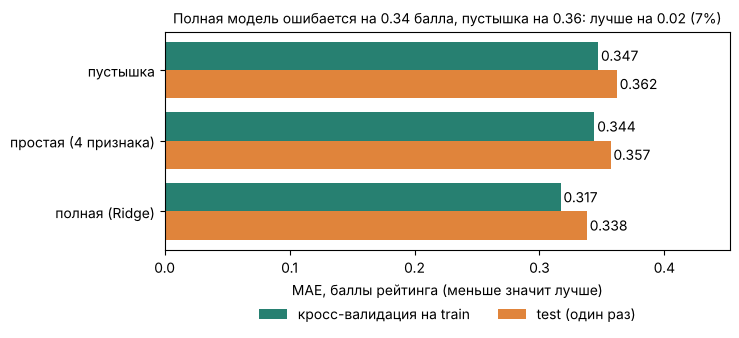

                      кросс-валидация   test
пустышка                        0.347  0.362
простая (4 признака)            0.344  0.357
полная (Ridge)                  0.317  0.338


In [136]:
# TEST, ОДИН РАЗ. Пустышку и простую модель обучаем на train, полная уже обучена.
dummy_model.fit(X_train, y_train)
simple_model.fit(X_train, y_train)
test_mae = test_scores({"пустышка": dummy_model, "простая (4 признака)": simple_model, f"полная ({full_name})": final_model},
                       X_test, y_test)

dummy_te, simple_te, full_te = test_mae["пустышка"], test_mae["простая (4 признака)"], test_mae[f"полная ({full_name})"]
gain_te = dummy_te - full_te
title = (f"Полная модель ошибается на {full_te:.2f} балла, пустышка на {dummy_te:.2f}: "
         + (f"лучше на {gain_te:.2f} ({gain_te / dummy_te * 100:.0f}%)" if gain_te > 0 else "не лучше пустышки"))
ladder_plot(ladder_cv, test_mae, title, path="figures/baseline.png")
print(pd.DataFrame({"кросс-валидация": ladder_cv, "test": test_mae}).round(3))

In [137]:
# служебные переменные и запись в журнал (вывод по baseline ниже, обычным текстом)
better = gain_te > 0
modest = better and gain_te / dummy_te < 0.10
log("baseline", f"MAE test: пустышка {dummy_te:.3f}, простая {simple_te:.3f}, полная {full_te:.3f}; test использован один раз", len(X_test))

**Вывод.** На test пустышка (всегда медиана 3,25) ошибается в среднем на 0,362 балла, простая модель на 4 признаках на 0,357, полная модель (Ridge) на 0,338. Значит, полная модель лучше пустышки на 0,024 балла, это около 7% её ошибки.

Простая модель почти не лучше пустышки (на кросс-валидации 0,344 против 0,347): четыре придуманных мной признака сами по себе почти ничего не добавляют. Улучшение даёт остальная подготовка (страна, страна компании, производитель, состав), хотя вклад каждой части я отдельно не проверяла. Ridge и градиентный бустинг показали одинаковую ошибку на кросс-валидации (0,317), поэтому выбрана более простая модель, Ridge.

Кросс-валидация и test не совпадают: у полной модели 0,317 и 0,338. Но и у пустышки 0,347 и 0,362, то есть test просто чуть тяжелее для всех трёх ступеней. Разрыв между пустышкой и полной моделью немного сузился (0,030 на кросс-валидации и 0,024 на test), но не исчез, поэтому оценка честная, а прирост небольшой, но настоящий.

Улучшение скромное, потому что оценки собраны в узком диапазоне (около 86% между 2,75 и 3,75), и пустышка уже ошибается мало. Ошибка 0,338 больше одной ступени шкалы (0,25): модель грубо отличает плохую плитку от хорошей, но точно оценку не предсказывает.

---
## 14. Выводы  ·  вместе с README: 15 баллов

Выводы собираются из чисел тетради, поэтому не расходятся с таблицами выше. Скопируйте результат в текстовую ячейку и перепишите своими словами: преподаватель может попросить объяснить любой пункт.

In [138]:
# числа для README (выводы ниже, обычным текстом)
n_total, n_miss = len(clean_df), int(clean_df["ingredients_missing"].sum())
miss_means = clean_df.groupby("ingredients_missing")[TARGET].mean()

**Выводы**

1. **О данных.** После очистки не потеряна ни одна строка: осталось 2 530 плиток. У 87 плиток (около 3%) не записан состав, и это «не знаем», а не «нет»: их средняя оценка ниже (2,81 против 3,21). Цель узкая: медиана 3,25, около 86% оценок между 2,75 и 3,75.
2. **Утечка.** Слова эксперта (`most_memorable_characteristics`) снижают ошибку на кросс-валидации с 0,318 до 0,259, но они появляются только после дегустации, поэтому в модель не идут. Название плитки тоже не берём.
3. **Честное сравнение.** На test пустышка ошибается на 0,362, простая модель на 0,357, полная (Ridge) на 0,338. Полная лучше пустышки на 0,024 балла (7%). Test использован один раз, и он оказался чуть тяжелее кросс-валидации для всех трёх ступеней.
4. **Что сработало, а что нет.** Полная модель лучше простой (0,317 против 0,344 на кросс-валидации): выигрыш дают страна, производитель и состав, а не мои четыре признака. Градиентный бустинг не лучше Ridge (оба 0,317). Подготовка внутри `Pipeline` (медианы, масштаб, редкие страны и код компании учатся только на train) позволила не подсматривать в test.
5. **Что сделала бы дальше.** Добавить то, чего нет в таблице (сорт какао, ферментация, способ обжарки, цена): скорее всего, это даст больше, чем подбор модели, но я это не проверяла. Проверить модель на отзывах следующих лет, а не на случайной части (год отзыва описывает эксперта, и случайное деление могло быть оптимистичным). Отдельно проверить вклад каждой группы признаков.

---
## 15. README  ·  вместе с разделом 14: 15 баллов

Сначала сохраняем модель в файл и проверяем, что она работает на плитке, которой не было в данных (незнакомая страна, новая компания, пустое значение). Потом README собирается кодом из переменных тетради: журнал, результаты и выводы попадают в файл сами.

In [139]:
Path("model").mkdir(exist_ok=True)
MODEL_PATH = "model/chocolate_rating_model.joblib"

# три новые плитки: незнакомая страна и компания, обычная плитка, пустой процент какао
new_bars = X_train.head(3).copy()
new_bars["country_of_bean_origin"] = ["Kazakhstan", new_bars["country_of_bean_origin"].iloc[1], new_bars["country_of_bean_origin"].iloc[2]]
new_bars["company_manufacturer"] = ["Новая компания", new_bars["company_manufacturer"].iloc[1], new_bars["company_manufacturer"].iloc[2]]
new_bars["cocoa_percent"] = [85.0, 70.0, np.nan]

pred = final_model.predict(new_bars)
print("предсказанная оценка новых плиток:", pred.round(2))

joblib.dump(final_model, MODEL_PATH)
loaded = joblib.load(MODEL_PATH)
print("файл модели:", Path(MODEL_PATH).stat().st_size // 1024, "КБ; ответы после загрузки совпадают:", bool(np.allclose(loaded.predict(new_bars), pred)))

MODEL_INPUT_COLS = ["country_of_bean_origin", "company_location", "company_manufacturer", "cocoa_percent", "n_ingredients",
                    "review_date", "ingredients_missing", "has_sugar", "has_sweetener", "has_cocoa_butter",
                    "has_vanilla", "has_lecithin", "has_salt"]

предсказанная оценка новых плиток: [2.79 3.04 3.4 ]
файл модели: 22 КБ; ответы после загрузки совпадают: True


In [140]:
# README собирается из переменных тетради
Path("figures").mkdir(exist_ok=True)

# график страны для README
cg = clean_df.groupby("country_of_bean_origin")[TARGET].agg(["mean", "size"])
cg = cg[cg["size"] >= 20].sort_values("mean")
fig, ax = plt.subplots(figsize=(7.5, 6))
bars = ax.barh(cg.index, cg["mean"], color=TEAL)
ax.axvline(clean_df[TARGET].mean(), color=ORANGE, ls="--", label="по всем данным")
ax.bar_label(bars, fmt="%.2f", padding=2)
ax.set_xlim(cg["mean"].min() - 0.15, cg["mean"].max() + 0.1)
ax.set_title(f"Средняя оценка по странам: от {cg['mean'].min():.2f} ({cg['mean'].idxmin()}) до {cg['mean'].max():.2f} ({cg['mean'].idxmax()})", fontsize=10)
ax.set_xlabel("средняя оценка rating, баллы (ось не с нуля)")
ax.set_ylabel("страна происхождения бобов")
ax.legend(loc="lower right")
plt.tight_layout()
fig.savefig("figures/country_mean_rating.png", dpi=150, bbox_inches="tight")
plt.close(fig)


def md_table(frame):
    cols = list(frame.columns)
    lines = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    for _, row in frame.iterrows():
        lines.append("| " + " | ".join(str(v).replace("|", "/") for v in row) + " |")
    return "\n".join(lines)


journal_table = md_table(pd.DataFrame([(k, v["решение"], v["строк"]) for k, v in journal.items()], columns=["шаг", "решение", "строк"]))
leak_md = md_table(leak_table[leak_table["берём или нет"] == "не берём"][["столбец", "когда становится известен", "почему"]])
results_md = md_table(pd.DataFrame({"модель": list(ladder_cv), "MAE на кросс-валидации": [f"{v:.3f}" for v in ladder_cv.values()],
                                    "MAE на test": [f"{v:.3f}" for v in test_mae.values()]}))

# находки EDA с числами
mid = clean_df[(clean_df["cocoa_percent"] > 65) & (clean_df["cocoa_percent"] <= 75)][TARGET].median()
dark = clean_df[clean_df["cocoa_percent"] > 80][TARGET].median()
known_df = clean_df[clean_df["ingredients_missing"] == 0]
simple_med = known_df[known_df["n_ingredients"].isin([2, 3])][TARGET].median()
rich_med = known_df[known_df["n_ingredients"].isin([4, 5])][TARGET].median()

readme = f"""# Какую оценку получит плитка шоколада: от сырых данных к честной модели

**Задача.** Предсказать экспертную оценку плитки шоколада `rating` (от 1 до 4) по производителю, происхождению бобов, проценту какао и составу, до того как плитку попробовали. Регрессия, метрика MAE (средняя абсолютная ошибка в баллах).

**Данные.** Рейтинги шоколада (Flavors of Cacao, TidyTuesday 2022-01-18): {DATA_URL}. {len(raw)} строк и {raw.shape[1]} столбцов. Одна строка это один экспертный отзыв на одну плитку.

## Что сделано с данными

{journal_table}

## Главное из EDA

* Цель узкая: медиана {clean_df[TARGET].median()}, около {clean_df[TARGET].between(2.75, 3.75).mean() * 100:.0f}% оценок между 2,75 и 3,75.
* Процент какао связан с оценкой слабо: у плиток 66-75% медиана {mid}, у очень тёмных (больше 80%) {dark}.
* Простые плитки (2-3 ингредиента) оцениваются выше: медиана {simple_med} против {rich_med} у плиток с 4-5 ингредиентами.
* Состав не записан у {n_miss} плиток, и их средняя оценка ниже: {miss_means.get(1, float('nan')):.2f} против {miss_means.get(0, float('nan')):.2f}.
* Средняя оценка по странам происхождения бобов (у стран с 20 и больше плитками) меняется от {cg['mean'].min():.2f} ({cg['mean'].idxmin()}) до {cg['mean'].max():.2f} ({cg['mean'].idxmax()}).

![оценка по странам](figures/country_mean_rating.png)

## Утечка

Какие столбцы не берём и почему:

{leak_md}

Проверка моделью: с описанием вкуса от эксперта MAE на кросс-валидации {words_cv:.3f}, без него {base_cv:.3f}.

## Результаты

{results_md}

На test: пустышка {dummy_te:.3f}, полная модель ({full_name}) {full_te:.3f}. Модель {'лучше пустышки на ' + format(gain_te, '.3f') + ' балла (' + format(gain_te / dummy_te * 100, '.0f') + '%)' if better else 'не лучше пустышки'}. Test использован один раз.

![лестница baseline](figures/baseline.png)

## Выводы

1. После очистки {n_total} плиток без потерь строк; пропуск состава у {n_miss} плиток это «не знаем», а не «нет».
2. Слова эксперта после дегустации (`most_memorable_characteristics`) подсказывают ответ (MAE {base_cv:.3f} без них, {words_cv:.3f} с ними), но для новой плитки их нет, поэтому в модель не идут.
3. Полная модель ({full_name}) ошибается на {full_te:.3f} балла на test, пустышка на {dummy_te:.3f}.
4. Подготовка (медианы, масштаб, редкие страны, код компании) учится только на train внутри `Pipeline`; настройки выбраны кросс-валидацией на train.
5. Дальше: добавить то, чего нет в таблице (сорт и ферментация бобов, обжарка, цена) и проверить модель на отзывах следующих лет.

## Модель

Обученная модель лежит в `model/chocolate_rating_model.joblib`. Чтобы её загрузить, сначала нужно определить функцию `add_features` из тетради (раздел 10), потому что она входит в Pipeline, потом `joblib.load(...)`. Входные столбцы: {', '.join(MODEL_INPUT_COLS)}.

## Как запустить

1. `pip install -r requirements.txt`
2. Открыть `project.ipynb` и выполнить все ячейки (данные скачиваются по ссылке автоматически).
"""
Path("README.md").write_text(readme, encoding="utf-8")
print("README.md записан, символов:", len(readme))
display(Markdown(readme))

README.md записан, символов: 4858


# Какую оценку получит плитка шоколада: от сырых данных к честной модели

**Задача.** Предсказать экспертную оценку плитки шоколада `rating` (от 1 до 4) по производителю, происхождению бобов, проценту какао и составу, до того как плитку попробовали. Регрессия, метрика MAE (средняя абсолютная ошибка в баллах).

**Данные.** Рейтинги шоколада (Flavors of Cacao, TidyTuesday 2022-01-18): https://raw.githubusercontent.com/rfordatascience/tidytuesday/master/data/2022/2022-01-18/chocolate.csv. 2530 строк и 10 столбцов. Одна строка это один экспертный отзыв на одну плитку.

## Что сделано с данными

| шаг | решение | строк |
|---|---|---|
| загрузка | скачали chocolate.csv по ссылке, 10 столбцов | 2530 |
| цель | rating уже число от 1 до 4, преобразование не нужно | 2530 |
| дубли | удалили полные дубли: 0; повторы ref не дубли, это номер записи | 2530 |
| пробелы | убрали лишние пробелы по краям в текстовых столбцах | 2530 |
| невозможные значения | 5 правил (рейтинг 1-4 и кратен 0.25, какао 0-100%, год 2006-2021, пустые названия); удалили строк: 0 | 2530 |
| пропуски: ingredients | не знаем: флаг ingredients_missing (1 у 87 строк), в тексте Unknown | 2530 |
| тип: cocoa_percent | текст '76%' -> число 76.0 | 2530 |
| тип: ingredients | разобрали строку: n_ingredients и 6 флагов; для Unknown n_ingredients = 3 (самое частое) | 2530 |
| столбец ref | удалили: служебный номер записи, не признак | 2530 |
| выбросы | оставили все: значения реальные (какао 42-100%, низкие оценки); логарифм не нужен, хвосты короткие | 2530 |
| clean | собрали все шаги в функцию clean(raw), сторожа assert пройдены | 2530 |
| новые признаки | is_blend, cocoa_dist70, n_additives, made_in_origin: функция add_features, считается по одной строке | 2530 |
| категории | OneHotEncoder(min_frequency=20, редкие в infrequent) для страны и страны компании; компания через TargetEncoder; признаков 59 | 2024 |
| утечка | не берём most_memorable_characteristics (слова после дегустации; MAE 0.318 без слов и 0.259 со словами) и название плитки | 2024 |
| baseline | MAE test: пустышка 0.362, простая 0.357, полная 0.338; test использован один раз | 506 |

## Главное из EDA

* Цель узкая: медиана 3.25, около 86% оценок между 2,75 и 3,75.
* Процент какао связан с оценкой слабо: у плиток 66-75% медиана 3.25, у очень тёмных (больше 80%) 3.0.
* Простые плитки (2-3 ингредиента) оцениваются выше: медиана 3.25 против 3.0 у плиток с 4-5 ингредиентами.
* Состав не записан у 87 плиток, и их средняя оценка ниже: 2.81 против 3.21.
* Средняя оценка по странам происхождения бобов (у стран с 20 и больше плитками) меняется от 3.04 (Blend) до 3.29 (Vietnam).

![оценка по странам](figures/country_mean_rating.png)

## Утечка

Какие столбцы не берём и почему:

| столбец | когда становится известен | почему |
|---|---|---|
| specific_bean_origin_or_bar_name | до дегустации | очень много разных значений: почти название-метка, по нему модель запоминает конкретные плитки, а не закономерности |
| most_memorable_characteristics | ПОСЛЕ дегустации | слова, которыми эксперт описал вкус после дегустации: для новой плитки их не существует; проверено моделью |
| ref | служебный номер записи в базе | удалён ещё на этапе 1 |

Проверка моделью: с описанием вкуса от эксперта MAE на кросс-валидации 0.259, без него 0.318.

## Результаты

| модель | MAE на кросс-валидации | MAE на test |
|---|---|---|
| пустышка | 0.347 | 0.362 |
| простая (4 признака) | 0.344 | 0.357 |
| полная (Ridge) | 0.317 | 0.338 |

На test: пустышка 0.362, полная модель (Ridge) 0.338. Модель лучше пустышки на 0.024 балла (7%). Test использован один раз.

![лестница baseline](figures/baseline.png)

## Выводы

1. После очистки 2530 плиток без потерь строк; пропуск состава у 87 плиток это «не знаем», а не «нет».
2. Слова эксперта после дегустации (`most_memorable_characteristics`) подсказывают ответ (MAE 0.318 без них, 0.259 с ними), но для новой плитки их нет, поэтому в модель не идут.
3. Полная модель (Ridge) ошибается на 0.338 балла на test, пустышка на 0.362.
4. Подготовка (медианы, масштаб, редкие страны, код компании) учится только на train внутри `Pipeline`; настройки выбраны кросс-валидацией на train.
5. Дальше: добавить то, чего нет в таблице (сорт и ферментация бобов, обжарка, цена) и проверить модель на отзывах следующих лет.

## Модель

Обученная модель лежит в `model/chocolate_rating_model.joblib`. Чтобы её загрузить, сначала нужно определить функцию `add_features` из тетради (раздел 10), потому что она входит в Pipeline, потом `joblib.load(...)`. Входные столбцы: country_of_bean_origin, company_location, company_manufacturer, cocoa_percent, n_ingredients, review_date, ingredients_missing, has_sugar, has_sweetener, has_cocoa_butter, has_vanilla, has_lecithin, has_salt.

## Как запустить

1. `pip install -r requirements.txt`
2. Открыть `project.ipynb` и выполнить все ячейки (данные скачиваются по ссылке автоматически).


---
## 16. Финальная проверка  ·  15 баллов

`requirements.txt`, проверка файлов, один архив для загрузки на GitHub. Потом «Среда выполнения», затем «Перезапустить сеанс и выполнить все»: тетрадь должна пройти от начала до конца без ошибок. Сохраните её после запуска (с выводами), скачайте как `project.ipynb`.

In [141]:
import zipfile

print(write_requirements())

FILES = ["README.md", "requirements.txt", "data/chocolate_clean.csv", MODEL_PATH,
         "figures/baseline.png", "figures/country_mean_rating.png"]
missing_files = [f for f in FILES if not Path(f).exists()]
assert not missing_files, f"нет файлов: {missing_files}"

with zipfile.ZipFile("midterm-chocolate-files.zip", "w") as z:
    for f in FILES:
        z.write(f)
print("\nв архиве midterm-chocolate-files.zip:")
for f in FILES:
    print(f"  {f:40s} {Path(f).stat().st_size // 1024:5d} КБ")
print("\nОсталось скачать project.ipynb (Файл, Скачать, Скачать .ipynb) и загрузить всё в репозиторий.")

['pandas==2.2.3', 'numpy==2.4.6', 'matplotlib==3.10.0', 'scikit-learn==1.6.1', 'joblib==1.6.0']

в архиве midterm-chocolate-files.zip:
  README.md                                    7 КБ
  requirements.txt                             0 КБ
  data/chocolate_clean.csv                   289 КБ
  model/chocolate_rating_model.joblib         22 КБ
  figures/baseline.png                        52 КБ
  figures/country_mean_rating.png            117 КБ

Осталось скачать project.ipynb (Файл, Скачать, Скачать .ipynb) и загрузить всё в репозиторий.


**Чек-лист перед сдачей.**

* ссылка на репозиторий открывается в режиме инкогнито;
* «Перезапустить сеанс и выполнить все» прошло без ошибок, тетрадь сохранена с выводами;
* под каждым разделом есть «Вывод»; у каждого графика заголовок-вывод и подписи осей;
* в репозитории: `README.md`, `project.ipynb`, `requirements.txt`, `data/chocolate_clean.csv`, `model/`, `figures/`;
* пустышка, простая и полная модель есть; test использован один раз.